# GraphSAGE + GAT Probability Ensemble — Elliptic Bitcoin

Validation-selected weighted probability ensemble. The temporal split and graph masks are reused; validation selects weight and threshold, and the test split is reported only after selection. Checkpoints and processed graph are local ignored files.


In [1]:
from pathlib import Path
import json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv, GATConv
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
 average_precision_score, roc_auc_score, classification_report, confusion_matrix,
 ConfusionMatrixDisplay, precision_recall_curve, roc_curve)
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
cwd=Path.cwd().resolve()
PROJECT_ROOT=cwd if (cwd/'data'/'processed').exists() else cwd.parent
MODEL_DIR=PROJECT_ROOT/'model'; RESULTS_DIR=PROJECT_ROOT/'results'/'Ensemble'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
GRAPH_PATH=PROJECT_ROOT/'data'/'processed'/'elliptic_graph.pt'
SAGE_PATH=MODEL_DIR/'best_graphsage_model.pt'; GAT_PATH=MODEL_DIR/'best_gat_model.pt'
for p in (GRAPH_PATH,SAGE_PATH,GAT_PATH):
    if not p.exists(): raise FileNotFoundError(f'Missing required local file: {p}')
graph_data=torch.load(GRAPH_PATH,map_location='cpu',weights_only=False)
for split in ('train','val','test'):
    mask=getattr(graph_data,f'{split}_mask')
    assert mask.dtype==torch.bool and mask.any()
    assert torch.all((graph_data.y[mask]==0)|(graph_data.y[mask]==1))
print('Device:',device,'Features:',tuple(graph_data.x.shape),'Edges:',tuple(graph_data.edge_index.shape))
print('Split counts:',{s:int(getattr(graph_data,f'{s}_mask').sum()) for s in ('train','val','test')})


C:\Users\nakul\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu Features: (203769, 165) Edges: (2, 468710)
Split counts: {'train': 29894, 'val': 7829, 'test': 8841}


## Load the baseline checkpoints

The architectures below must match the architectures used to train the saved checkpoints.


In [2]:
class GraphSAGE(torch.nn.Module):
    def __init__(self,n_features,hidden=64,n_classes=2,dropout=.5):
        super().__init__(); self.conv1=SAGEConv(n_features,hidden); self.conv2=SAGEConv(hidden,n_classes); self.dropout=dropout
    def forward(self,x,edge_index):
        x=F.relu(self.conv1(x,edge_index)); x=F.dropout(x,p=self.dropout,training=self.training); return self.conv2(x,edge_index)
class GAT(torch.nn.Module):
    def __init__(self,n_features,hidden=16,heads=4,n_classes=2,dropout=.5):
        super().__init__(); self.feature_dropout=dropout
        self.conv1=GATConv(n_features,hidden,heads=heads,concat=True,dropout=dropout)
        self.conv2=GATConv(hidden*heads,n_classes,heads=1,concat=False,dropout=dropout)
    def forward(self,x,edge_index):
        x=F.dropout(x,p=self.feature_dropout,training=self.training); x=F.elu(self.conv1(x,edge_index)); x=F.dropout(x,p=self.feature_dropout,training=self.training); return self.conv2(x,edge_index)
def load_state(path):
    obj=torch.load(path,map_location=device,weights_only=True)
    if isinstance(obj,dict) and 'state_dict' in obj: obj=obj['state_dict']
    return obj
sage=GraphSAGE(graph_data.x.shape[1]).to(device); sage.load_state_dict(load_state(SAGE_PATH)); sage.eval()
gat=GAT(graph_data.x.shape[1]).to(device); gat.load_state_dict(load_state(GAT_PATH)); gat.eval()
x=graph_data.x.to(device); edge_index=graph_data.edge_index.to(device)
@torch.no_grad()
def fraud_probs(model): return torch.softmax(model(x,edge_index),dim=1)[:,1].cpu().numpy()
sage_prob=fraud_probs(sage); gat_prob=fraud_probs(gat)
val_mask=graph_data.val_mask.numpy(); test_mask=graph_data.test_mask.numpy()
y_val=graph_data.y[graph_data.val_mask].numpy(); y_test=graph_data.y[graph_data.test_mask].numpy()
sage_val,sage_test=sage_prob[val_mask],sage_prob[test_mask]
gat_val,gat_test=gat_prob[val_mask],gat_prob[test_mask]
print('Validation/test prediction arrays ready.')


Validation/test prediction arrays ready.


## Select ensemble weight and threshold on validation only


Frozen validation-selected configuration: {'alpha_graphsage': 1.0, 'alpha_gat': 0.0, 'threshold': 0.82, 'validation_fraud_precision': 0.6962616822429907, 'validation_fraud_recall': 0.6622222222222223, 'validation_fraud_f1': 0.6788154897494305}


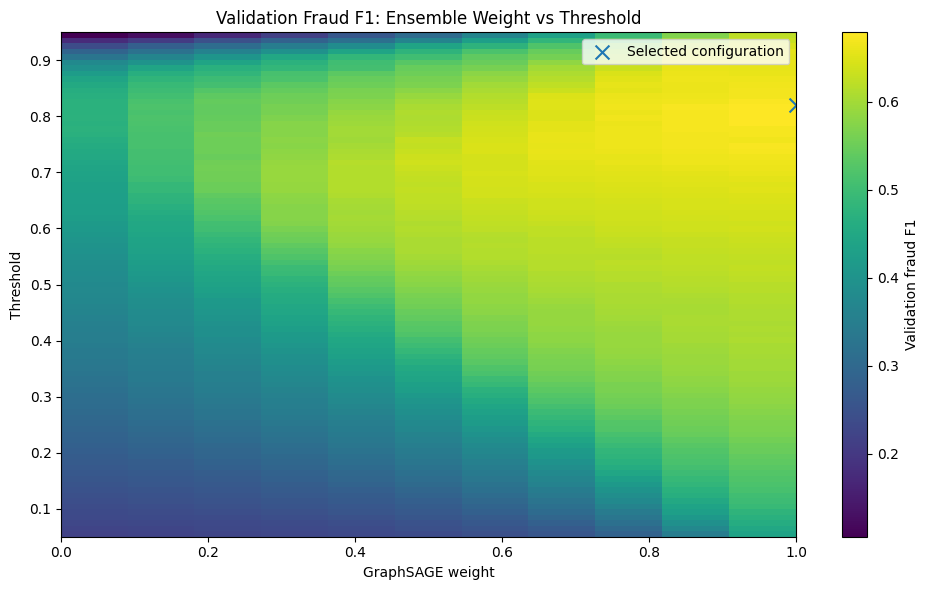

In [3]:
candidates=[]
for alpha in np.round(np.linspace(0,1,11),2):
    p=alpha*sage_val+(1-alpha)*gat_val
    for threshold in np.round(np.linspace(.05,.95,91),2):
        pred=(p>=threshold).astype(int)
        candidates.append({'alpha_graphsage':float(alpha),'alpha_gat':float(1-alpha),'threshold':float(threshold),
          'validation_fraud_precision':precision_score(y_val,pred,zero_division=0),
          'validation_fraud_recall':recall_score(y_val,pred,zero_division=0),
          'validation_fraud_f1':f1_score(y_val,pred,zero_division=0)})
val_df=pd.DataFrame(candidates)
val_df.to_csv(RESULTS_DIR/'validation_search.csv',index=False)
best=val_df.sort_values(['validation_fraud_f1','validation_fraud_precision','validation_fraud_recall','alpha_graphsage','threshold'],ascending=[False,False,False,False,False]).iloc[0]
alpha=float(best.alpha_graphsage); threshold=float(best.threshold)
print('Frozen validation-selected configuration:',best.to_dict())
plt.figure(figsize=(10,6)); pivot=val_df.pivot(index='threshold',columns='alpha_graphsage',values='validation_fraud_f1')
plt.imshow(pivot.values,aspect='auto',origin='lower',extent=[pivot.columns.min(),pivot.columns.max(),pivot.index.min(),pivot.index.max()])
plt.colorbar(label='Validation fraud F1'); plt.scatter([alpha],[threshold],marker='x',s=100,label='Selected configuration')
plt.xlabel('GraphSAGE weight'); plt.ylabel('Threshold'); plt.title('Validation Fraud F1: Ensemble Weight vs Threshold'); plt.legend(); plt.tight_layout()
plt.savefig(RESULTS_DIR/'validation_f1_heatmap.png',dpi=160,bbox_inches='tight'); plt.show()


## Final test evaluation and saved plots

Do not use test results to change the selected weight or threshold. Baseline values below are recorded results; the ensemble uses a validation-selected threshold, so this decision-rule difference should be disclosed.


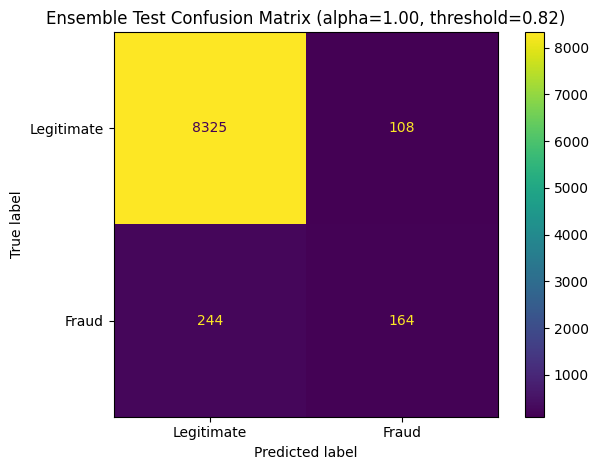

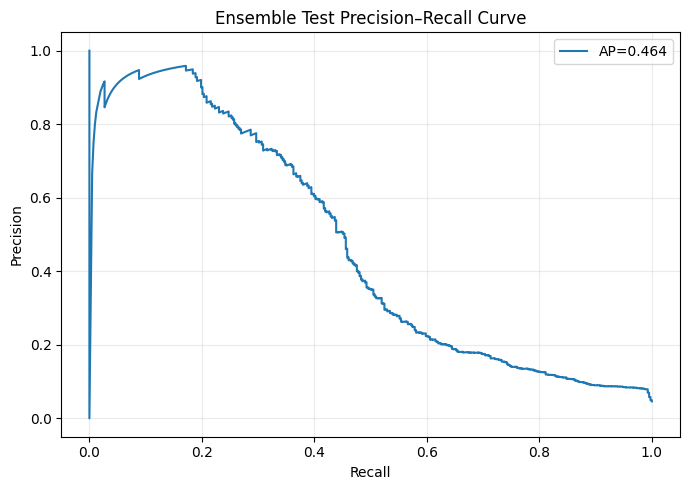

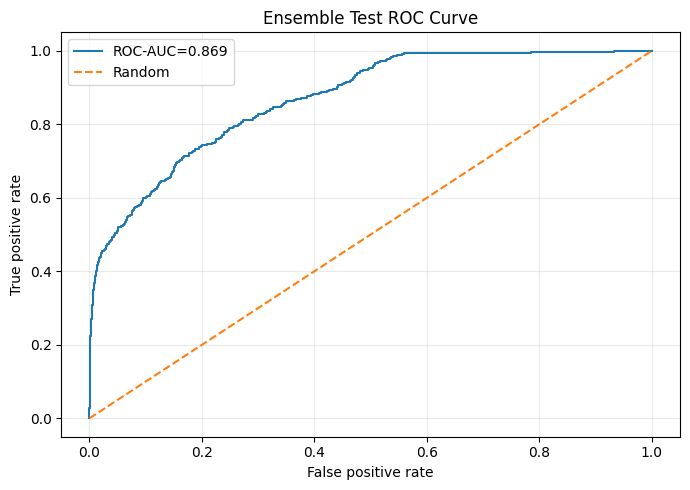

{
  "accuracy": 0.9601854993778984,
  "fraud_precision": 0.6029411764705882,
  "fraud_recall": 0.4019607843137255,
  "fraud_f1": 0.4823529411764706,
  "pr_auc_average_precision": 0.4641320113830945,
  "roc_auc": 0.8686599447083471
}
              precision    recall  f1-score   support

  Legitimate       0.97      0.99      0.98      8433
       Fraud       0.60      0.40      0.48       408

    accuracy                           0.96      8841
   macro avg       0.79      0.69      0.73      8841
weighted avg       0.95      0.96      0.96      8841



In [4]:
ensemble_prob=alpha*sage_test+(1-alpha)*gat_test
pred=(ensemble_prob>=threshold).astype(int)
metrics={'accuracy':float(accuracy_score(y_test,pred)),'fraud_precision':float(precision_score(y_test,pred,zero_division=0)),
 'fraud_recall':float(recall_score(y_test,pred,zero_division=0)),'fraud_f1':float(f1_score(y_test,pred,zero_division=0)),
 'pr_auc_average_precision':float(average_precision_score(y_test,ensemble_prob)),
 'roc_auc':float(roc_auc_score(y_test,ensemble_prob)) if np.unique(y_test).size==2 else None}
results={'experiment':'GraphSAGE_GAT_probability_ensemble','dataset':'Elliptic Bitcoin','seed':SEED,
 'selection_split':'validation','alpha_graphsage':alpha,'alpha_gat':1-alpha,'threshold':threshold,'test_metrics':metrics,
 'classification_report':classification_report(y_test,pred,target_names=['Legitimate','Fraud'],output_dict=True,zero_division=0)}
with open(RESULTS_DIR/'ensemble_metrics.json','w') as f: json.dump(results,f,indent=2)
with open(RESULTS_DIR/'metrics.csv','w') as f: pd.DataFrame([{'model':'GraphSAGE+GAT Ensemble',**metrics}]).to_csv(f,index=False)
cm=confusion_matrix(y_test,pred,labels=[0,1]); disp=ConfusionMatrixDisplay(cm,display_labels=['Legitimate','Fraud']); disp.plot(values_format='d')
plt.title(f'Ensemble Test Confusion Matrix (alpha={alpha:.2f}, threshold={threshold:.2f})'); plt.tight_layout(); plt.savefig(RESULTS_DIR/'confusion_matrix.png',dpi=160,bbox_inches='tight'); plt.show()
precision,recall,_=precision_recall_curve(y_test,ensemble_prob)
plt.figure(figsize=(7,5)); plt.plot(recall,precision,label=f'AP={metrics["pr_auc_average_precision"]:.3f}'); plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Ensemble Test Precision–Recall Curve'); plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.savefig(RESULTS_DIR/'precision_recall_curve.png',dpi=160,bbox_inches='tight'); plt.show()
fpr,tpr,_=roc_curve(y_test,ensemble_prob)
plt.figure(figsize=(7,5)); plt.plot(fpr,tpr,label=f'ROC-AUC={metrics["roc_auc"]:.3f}'); plt.plot([0,1],[0,1],'--',label='Random'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.title('Ensemble Test ROC Curve'); plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.savefig(RESULTS_DIR/'roc_curve.png',dpi=160,bbox_inches='tight'); plt.show()
print(json.dumps(metrics,indent=2)); print(classification_report(y_test,pred,target_names=['Legitimate','Fraud'],zero_division=0))


## Output files

Running the notebook creates `results/Ensemble/` and saves `ensemble_metrics.json`, `metrics.csv`, `validation_search.csv`, `confusion_matrix.png`, `precision_recall_curve.png`, `roc_curve.png`, and `validation_f1_heatmap.png`. Generated results and checkpoints are not committed; the folder README is tracked instead.
